# Pathway Enrichment Analysis for Figure 5

This notebook performs HALLMARK pathway enrichment analyses for the Xenium Prime cervical cancer sample shown in Figure 5. The analysis includes two parts:

1. **Tumor subtype-level analysis:** identifies significantly upregulated genes in stressed, proliferative, and EMT-like tumor cells and calculates their enriched HALLMARK pathways.
2. **Niche-level analysis:** identifies niche-specific upregulated genes within each tumor subtype across five representative niches (`C9`, `C4`, `C8`, `C11`, and `C5`) and calculates their enriched HALLMARK pathways.

Differential expression results generated in the upstream Python notebook are loaded from `./Outputs/`. Pathway enrichment is performed using the R package `clusterProfiler`.

### Table of Contents

- [1. HALLMARK enrichment across tumor cell subtypes](#1-hallmark-enrichment-across-tumor-cell-subtypes)
- [2. HALLMARK enrichment across niches within tumor cell subtypes](#2-hallmark-enrichment-across-niches-within-tumor-cell-subtypes)

In [1]:
suppressWarnings(
  suppressPackageStartupMessages({
    library(ggplot2)
    library(dplyr)
    library(org.Hs.eg.db)
    library(stringr)
    library(clusterProfiler)
    library(stringr)
  })
)

## 1. HALLMARK enrichment across tumor cell subtypes

Load differential expression results for the three tumor cell subtypes

In [2]:
deg_df <- read.csv('./Outputs/DEGs_Cervical_cancer_tumor_cells_3_subtypes.csv', row.names = 1, check.names = F)

# Select significantly upregulated genes in each tumor cell subtype
markers_df <- deg_df[which(deg_df$logfoldchanges > 0.5 & deg_df$pvals_adj < 0.01), ]
table(markers_df$group)
head(deg_df)


     EMT-like tumor Proliferative tumor      Stressed tumor 
                247                 440                 259 

,group,gene,logfoldchanges,pvals,pvals_adj,scores
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
0,Stressed tumor,SPRR3,4.650398,0,0,340.2487
1,Stressed tumor,LCN2,3.758198,0,0,183.7702
2,Stressed tumor,CEACAM5,4.383301,0,0,172.7429
3,Stressed tumor,MALL,1.890538,0,0,161.6041
4,Stressed tumor,NAMPT,1.734166,0,0,127.1237
5,Stressed tumor,A2ML1,3.293894,0,0,120.7447


In [3]:
# Load HALLMARK gene sets
gmt <- read.gmt("h.all.v7.4.symbols.gmt")

# Perform HALLMARK enrichment for genes upregulated in stressed tumor cells
markers <- markers_df$gene[which(markers_df$group == 'Stressed tumor')]
egmt.up1 <- enricher(markers, TERM2GENE= gmt,
                   pvalueCutoff  = 0.05,
                   qvalueCutoff  = 0.05)
egmt.up1 <- as.data.frame(egmt.up1)
egmt.up1$Direction <- 'Stressed'

# Perform HALLMARK enrichment for genes upregulated in proliferative tumor cells
markers <- markers_df$gene[which(markers_df$group == 'Proliferative tumor')]
egmt.up2 <- enricher(markers, TERM2GENE= gmt,
                   pvalueCutoff  = 0.05,
                   qvalueCutoff  = 0.05)
egmt.up2 <- as.data.frame(egmt.up2)
egmt.up2$Direction <- 'Proliferative'

# Perform HALLMARK enrichment for genes upregulated in EMT-like tumor cells
markers <- markers_df$gene[which(markers_df$group == 'EMT-like tumor')]
egmt.up3 <- enricher(markers, TERM2GENE= gmt,
                   pvalueCutoff  = 0.05,
                   qvalueCutoff  = 0.05)
egmt.up3 <- as.data.frame(egmt.up3)
egmt.up3$Direction <- 'EMT-like'

egmt.up <- rbind(egmt.up1, egmt.up2, egmt.up3)
head(egmt.up)


,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count,Direction
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<chr>
HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_TNFA_SIGNALING_VIA_NFKB,20/127,200/4383,8.083454e-07,3.637554e-05,2.637759e-05,NAMPT/CDKN1A/KLF4/F3/MXD1/SERPINB2/DUSP5/SDC4/TNIP1/TIPARP/CCL20/IL1A/PLAUR/MAFF/TNFSF9/PFKFB3/CFLAR/ABCA1/RIPK2/HBEGF,20,Stressed
HALLMARK_IL2_STAT5_SIGNALING,HALLMARK_IL2_STAT5_SIGNALING,HALLMARK_IL2_STAT5_SIGNALING,18/127,199/4383,1.275650e-05,2.870212e-04,2.081323e-04,HOPX/EMP1/ECM1/BCL2L1/PIM1/MXD1/SH3BGRL2/MYO1E/PLSCR1/XBP1/HK2/IKZF2/CDCP1/TIAM1/MAFF/MUC1/PRKCH/PNP,18,Stressed
HALLMARK_INFLAMMATORY_RESPONSE,HALLMARK_INFLAMMATORY_RESPONSE,HALLMARK_INFLAMMATORY_RESPONSE,17/127,200/4383,5.100093e-05,7.650140e-04,5.547470e-04,NAMPT/CDKN1A/F3/MXD1/CD55/CCL20/IL1A/PLAUR/LYN/IL1R1/TNFSF9/IRAK2/ACVR2A/SEMA4D/ABCA1/RIPK2/HBEGF,17,Stressed
HALLMARK_COMPLEMENT,HALLMARK_COMPLEMENT,HALLMARK_COMPLEMENT,16/127,200/4383,1.775304e-04,1.997217e-03,1.448274e-03,PIM1/F3/SERPINB2/CD55/DUSP5/PLAT/PLSCR1/ADAM9/LGMN/PLAUR/LYN/MAFF/CD46/DOCK9/LTA4H/CD36,16,Stressed
HALLMARK_APOPTOSIS,HALLMARK_APOPTOSIS,HALLMARK_APOPTOSIS,12/127,161/4383,2.200639e-03,1.980575e-02,1.436206e-02,CDKN1A/EMP1/BCL2L1/PLAT/VDAC2/ERBB3/IL1A/BCL10/ERBB2/BIK/HMOX1/CFLAR,12,Stressed
HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_EARLY,13/127,200/4383,4.820949e-03,2.711784e-02,1.966440e-02,KLK10/KLF4/SCNN1A/CLDN7/CLIC3/XBP1/TIPARP/TIAM1/HSPB8/MUC1/MLPH/WWC1/FOXC1,13,Stressed


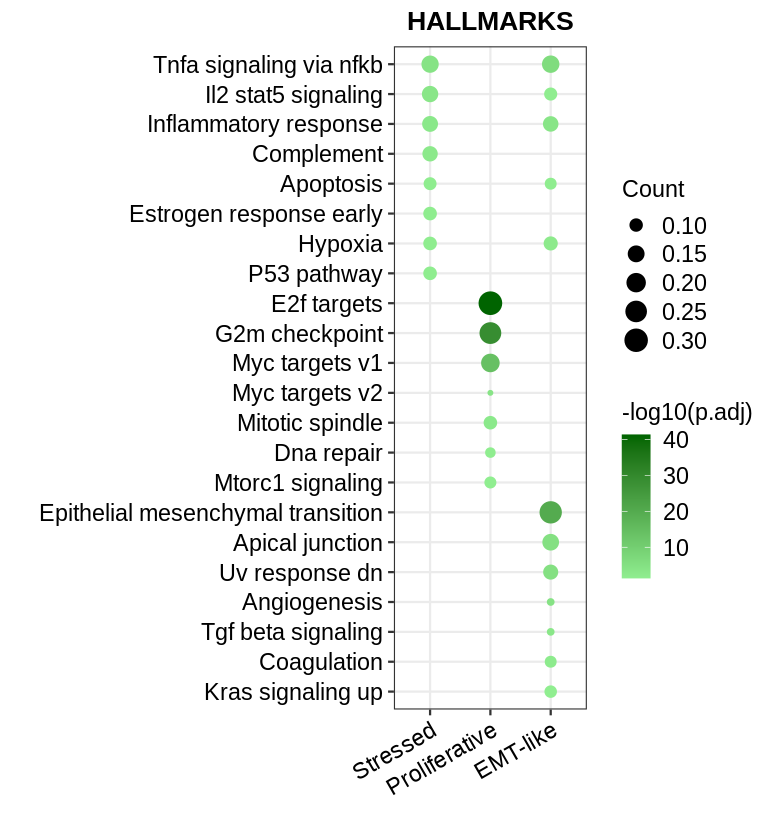

In [4]:
# Prepare enrichment results for visualization

# Calculate enrichment significance as −log10-adjusted P values
egmt.up <- egmt.up %>% mutate(negLog10_padj = -log10(p.adjust))
# Convert GeneRatio from a fraction to a numeric value
egmt.up$GeneRatio <- sapply(strsplit(as.character(egmt.up$GeneRatio), "/"), function(x) as.numeric(x[1]) / as.numeric(x[2]))
                            

# Format HALLMARK pathway names for visualization
egmt.up$Description <- substr(egmt.up$Description , 10, 50)
egmt.up$Description <- str_replace_all(egmt.up$Description, '_', ' ')
egmt.up$Description <- paste0(toupper(substr(egmt.up$Description, 1, 1)), 
                               tolower(substr(egmt.up$Description, 2, nchar(egmt.up$Description))))

# Set the display order of the three tumor subtypes
egmt.up$Direction <- factor(egmt.up$Direction, levels = c('Stressed', 'Proliferative', 'EMT-like'), ordered = TRUE)

# Order pathways by tumor subtype and enrichment significance
egmt.up <- egmt.up %>%
  arrange(Direction, desc(negLog10_padj))

description_levels <- egmt.up %>%
  arrange(Direction, desc(negLog10_padj)) %>%
  pull(Description) %>%
  unique()

egmt.up$Description <- factor(egmt.up$Description, 
                              levels = rev(description_levels))


# dotplot
p1 <- ggplot(egmt.up, aes(x = Direction, y = Description)) +
  geom_point(aes(size = GeneRatio, color = negLog10_padj)) +
  scale_color_gradient(low = "lightgreen", high = "darkgreen", name = "-log10(p.adj)") +
  labs(
    title = "HALLMARKS",
    x = "",
    y = "",
    color = expression(-log[10](p.adjust)),
    size = "Count"
  ) +
  theme_bw(base_size = 14) +  
  theme(
    text = element_text(color = "black", size = 14),  
    axis.text.y = element_text(size = 14, color = "black"),  
    axis.text.x = element_text(size = 14, color = "black", angle = 30, hjust = 1),  
    axis.title = element_text(size = 14, color = "black"), 
    plot.title = element_text(size = 16, face = "bold", color = "black", hjust = 0.5), 
    legend.title = element_text(size = 14, color = "black"),  
    legend.text = element_text(size = 14, color = "black")  
  )

options(repr.plot.width = 6.5, repr.plot.height = 7)
print(p1)

## 2. HALLMARK enrichment across niches within tumor cell subtypes

In [5]:
deg_df1 <- read.csv('./Outputs/DEGs_Stressed_tumor_across_5_niches.csv', row.names = 1, check.names = F)
deg_df1$Cell_Type <- 'Stressed'

deg_df2 <- read.csv('./Outputs/DEGs_Proliferative_tumor_across_5_niches.csv', row.names = 1, check.names = F)
deg_df2$Cell_Type <- 'Proliferative'

deg_df3 <- read.csv('./Outputs/DEGs_EMT-like_tumor_across_5_niches.csv', row.names = 1, check.names = F)
deg_df3$Cell_Type <- 'EMT-like'

deg_df <- rbind(deg_df1, deg_df2, deg_df3)
markers_df <- deg_df[which(deg_df$logfoldchanges > 0.3 & deg_df$pvals_adj < 0.05), ]
table(markers_df$Cell_Type, markers_df$group)
head(markers_df)

               
                 C11   C4   C5   C8   C9
  EMT-like       141   13   32   70   32
  Proliferative  510  105 1135  136   39
  Stressed       387  156 1202   57  107

,group,gene,logfoldchanges,pvals,pvals_adj,scores,Cell_Type
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
0,C4,HSPB1,0.9187468,0,0,83.65142,Stressed
1,C4,DSC3,0.7949482,0,0,62.84679,Stressed
2,C4,SLC2A1,1.5705140,0,0,54.43301,Stressed
3,C4,DSG3,0.7619440,0,0,49.17052,Stressed
4,C4,NDRG1,0.8873603,0,0,43.37498,Stressed
5,C4,APOL1,0.9976879,0,0,38.53545,Stressed


In [6]:
# Load HALLMARK gene sets
gmt <- read.gmt("h.all.v7.4.symbols.gmt")

# Split marker genes by niche and cell type
group_cell_combinations <- split(markers_df, list(markers_df$group, markers_df$Cell_Type))

# Perform HALLMARK pathway enrichment for each niche–cell type combination
enrichment_results <- lapply(names(group_cell_combinations), function(name) {
  subset_data <- group_cell_combinations[[name]]
  markers <- subset_data$gene
  if (length(markers) > 0) {
    egmt <- enricher(markers, TERM2GENE= gmt, pvalueCutoff = 0.05, qvalueCutoff = 1)
    if (!is.null(egmt)) {
      egmt_df <- as.data.frame(egmt)
      if (nrow(egmt_df) > 0) {  
        egmt_df$Direction <- unique(subset_data$group)
        egmt_df$Cell_Type <- unique(subset_data$Cell_Type)
        return(egmt_df)
      }
    }
  }
  return(NULL)
})

# Remove combinations without significant enrichment results
enrichment_results <- enrichment_results[!sapply(enrichment_results, is.null)]

# Combine enrichment results across all niches and cell types
egmt_all <- do.call(rbind, enrichment_results)

# Summarize the number of enriched pathways for each niche–cell type combination
table(egmt_all$Direction, egmt_all$Cell_Type)

     
      EMT-like Proliferative Stressed
  C11        1             7        4
  C4         1             7       11
  C5         0             7        7
  C8         3             9        7
  C9        10             7        8

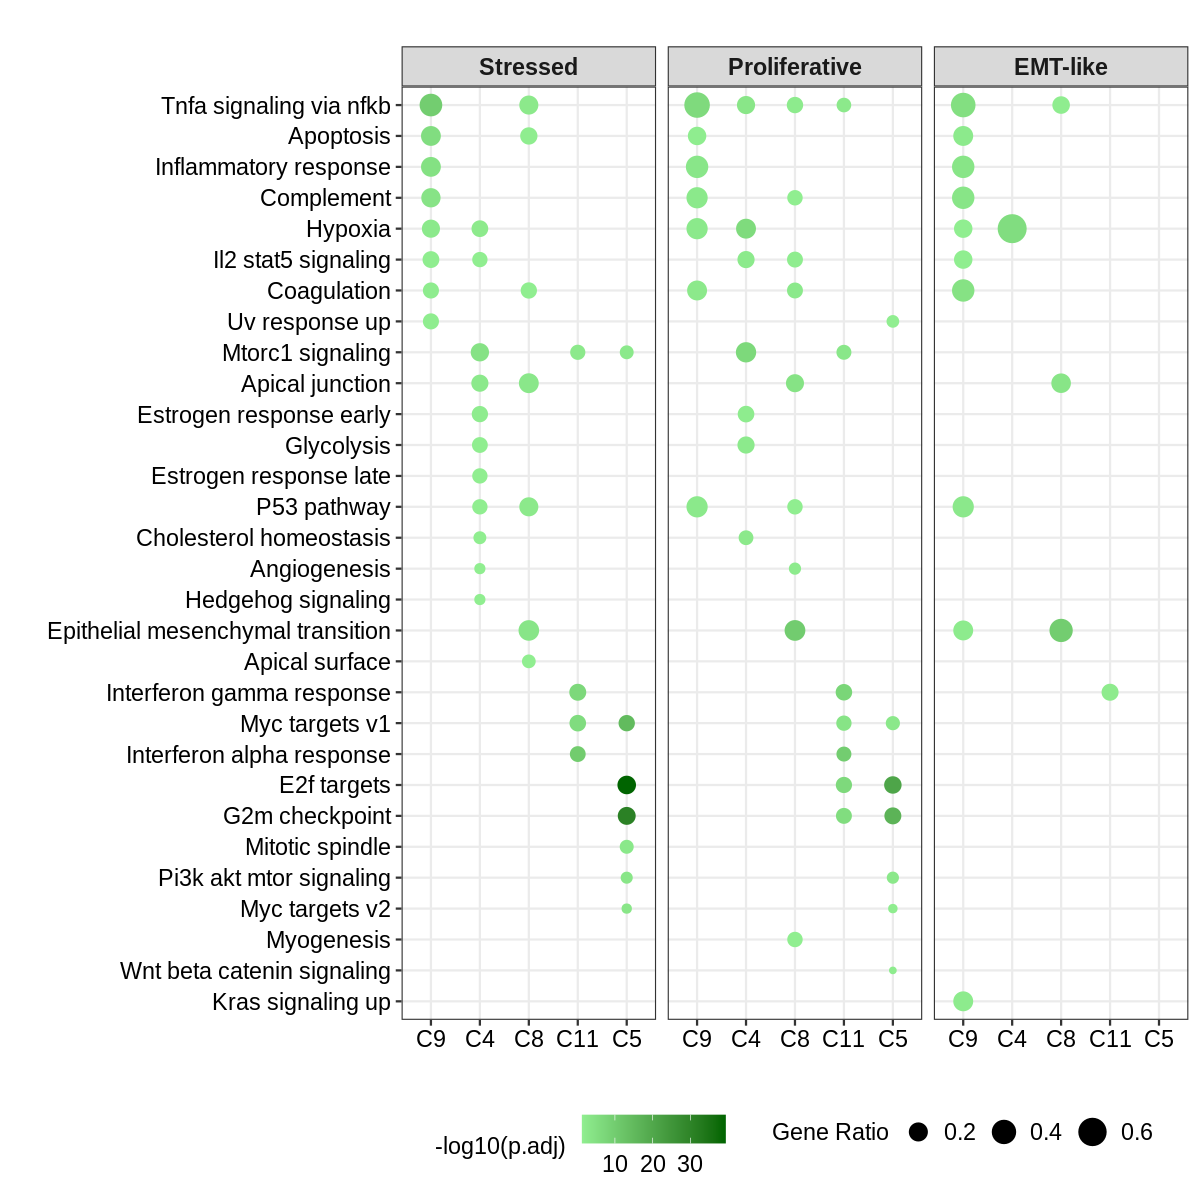

In [7]:
# Prepare enrichment results for visualization

# Calculate enrichment significance as −log10-adjusted P values
egmt.up <- egmt_all %>% mutate(negLog10_padj = -log10(p.adjust))
# Convert GeneRatio from a fraction to a numeric value
egmt.up$GeneRatio <- sapply(strsplit(as.character(egmt.up$GeneRatio), "/"), function(x) as.numeric(x[1]) / as.numeric(x[2]))
                                                        
egmt.up$Description <- substr(egmt.up$Description , 10, 50)
egmt.up$Description <- str_replace_all(egmt.up$Description, '_', ' ')
egmt.up$Description <- paste0(toupper(substr(egmt.up$Description, 1, 1)), 
                               tolower(substr(egmt.up$Description, 2, nchar(egmt.up$Description))))


options(repr.plot.width = 10, repr.plot.height = 10)

# Set the display order of tumor subtypes and niches
egmt.up$Cell_Type <- factor(egmt.up$Cell_Type, 
                            levels = c('Stressed', 'Proliferative', 'EMT-like'), 
                            ordered = TRUE)

egmt.up$Direction <- factor(egmt.up$Direction, 
                            levels = c('C9', 'C4', 'C8', 'C11', 'C5'), 
                            ordered = TRUE)

# Order pathways by tumor subtype, niche, and gene ratio
egmt.up <- egmt.up %>%
  arrange(Cell_Type, Direction, desc(GeneRatio))

description_levels <- egmt.up %>%
  pull(Description) %>%
  unique()

egmt.up$Description <- factor(egmt.up$Description, 
                              levels = rev(description_levels))

# Plot HALLMARK pathway enrichment across niches and tumor subtypes
p1 <- ggplot(egmt.up, aes(x = Direction, y = Description)) +
  geom_point(aes(size = GeneRatio, color = negLog10_padj)) +
  scale_color_gradient(low = "lightgreen", high = "darkgreen", name = "-log10(p.adj)") +
  scale_size_continuous(name = "Gene Ratio", range = c(1.5, 7.5)) +  
  labs(
    title = "",
    x = "",
    y = "",
    color = expression(-log[10](p.adjust)),
    size = "Gene Ratio"
  ) +
  theme_bw(base_size = 14) +  
  theme(
    text = element_text(color = "black", size = 14),  
    axis.text.y = element_text(size = 14, color = "black"),  
    axis.text.x = element_text(size = 14, color = "black"),  
    axis.title = element_text(size = 14, color = "black"),  
    plot.title = element_text(size = 16, color = "black", hjust = 0.5),  
    legend.title = element_text(size = 14, color = "black"),  
    legend.text = element_text(size = 14, color = "black"),
    strip.text = element_text(size = 14, face = "bold"), 
          legend.position = "bottom",  
    legend.direction = "horizontal", 
    legend.box = "horizontal"  
  ) +
  facet_grid(~ Cell_Type) 

print(p1)
